# 01 — Crop recommendation

## Goal and learning outcomes
Predict one of 22 crop labels from seven numerical features. Learn data inspection, exploration,
stratified splitting, model comparison, classification metrics and ranked predictions.

## Data dictionary
| Column | Meaning | Unit or limitation |
|---|---|---|
| N, P, K | Nitrogen, phosphorus and potassium inputs | Reference dataset values; measurement units undocumented |
| temperature | Temperature | Degrees Celsius in the reference |
| humidity | Relative humidity input | Percentage |
| ph | Soil acidity/alkalinity | pH scale |
| rainfall | Rainfall input | Reference labels say mm; accumulation period is undocumented |
| label | Crop to predict | 22 categories |

The source generates 100 examples per crop using predefined profiles and random noise. Therefore,
recognizable profile boundaries can make this task easy. Do not describe these rows as measured field data.

## Environment and imports

**What we do:** Locate the project and import the libraries used in this notebook.

**Why we do it:** Relative paths let this project work after it is moved or cloned. pandas handles tables, NumPy handles arrays, and Matplotlib draws graphs. The src package contains shared, readable code.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open this notebook from the project folder or its notebooks folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.data import SPECS, load_data
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Project:", ROOT.name)

Project: agrisense-college-mini


**Read the output:** The printed folder should be agrisense-college-mini. In VS Code select the project's .venv Python environment as the notebook kernel. Run cells from top to bottom.

## Load and inspect data

**What we do:** Read the CSV, preview its rows, check column types and summarize numerical values.

**Why we do it:** Inspecting real file contents avoids guessing the schema. load_data also rejects missing values, duplicate rows and non-finite numerical values instead of silently changing them.

In [2]:
KIND = "crop"
df = load_data(KIND)
spec = SPECS[KIND]
display(df.head())
display(df.dtypes.to_frame("Data type"))
display(df.describe().round(2))
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

,N,P,K,temperature,humidity,ph,rainfall,label
0,85.0,38.7,40.9,22.20,80.51,6.60,262.71,rice
1,78.6,44.9,41.4,22.70,81.75,6.97,212.34,rice
2,86.5,45.4,42.7,25.15,82.51,5.73,266.09,rice
3,95.2,42.5,42.6,24.89,82.56,6.46,280.67,rice
4,77.7,46.5,36.6,23.71,81.94,6.01,252.40,rice


,Data type
N,float64
P,float64
K,float64
temperature,float64
humidity,float64
ph,float64
rainfall,float64
label,str


,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,55.13,53.39,48.18,25.87,72.00,6.46,103.39
std,33.69,32.40,50.64,4.79,21.47,0.66,54.44
min,9.70,0.10,1.70,5.00,13.77,3.50,20.00
25%,27.30,26.58,20.40,22.71,60.38,6.01,65.62
50%,38.70,50.20,31.05,25.64,80.34,6.46,97.42
75%,86.90,67.40,49.30,28.60,89.86,6.88,124.98
max,143.80,148.20,206.50,50.00,99.90,9.50,317.20


Shape: (2200, 8)
Missing values: 0
Duplicate rows: 0


**Read the output:** Check that the printed columns match the data dictionary. If missing values or duplicates are introduced later, inspect their cause and document a cleaning strategy before training.

## Explore class balance and numerical relationships

**What we do:** Count examples per crop and plot correlations between numerical inputs.

**Why we do it:** Class balance affects how accuracy should be interpreted. Correlation reveals associations within this dataset, including associations caused by its generation rules.

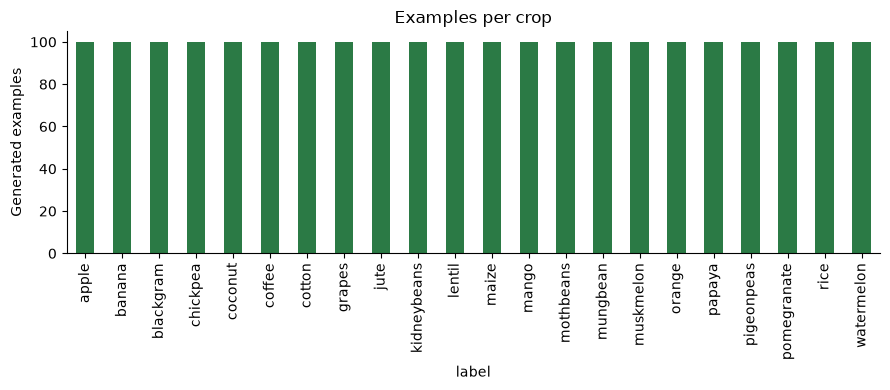

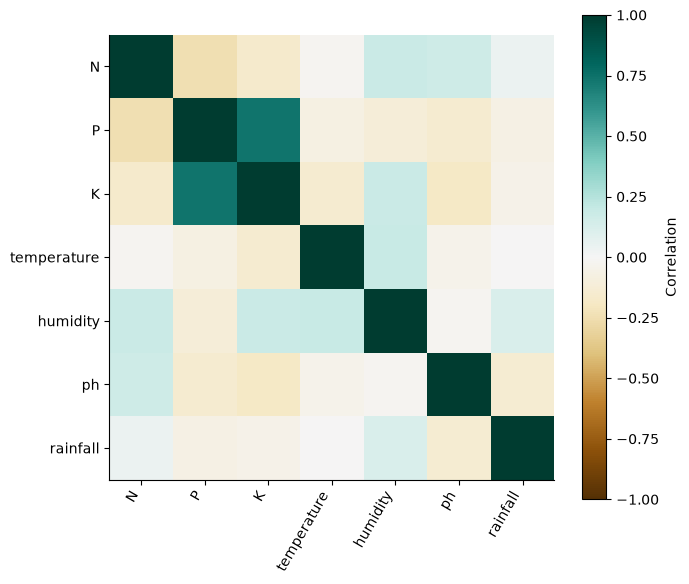

In [3]:
df["label"].value_counts().sort_index().plot.bar(color="#2b7a45")
plt.ylabel("Generated examples")
plt.title("Examples per crop")
plt.tight_layout()
plt.show()
corr = df[spec["numeric"]].corr()
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(image, ax=ax, label="Correlation")
plt.tight_layout()
plt.show()

**Read the output:** Each crop has 100 examples. Correlation ranges from -1 to +1 and describes linear association. It does not tell us whether a feature causes crop success.

## Features, target and independent split

**What we do:** Select only the declared input columns, then create an 80/20 train/test split.

**Why we do it:** The test labels must not influence fitting, preprocessing or model selection. Classification is stratified to preserve class proportions. Seed 42 makes the split reproducible.

In [4]:
from src.ml import split_data, make_pipeline, train_model, predict, feature_importance
X_train, X_test, y_train, y_test = split_data(KIND, df)
print("Input columns:", X_train.columns.tolist())
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)
print("Index overlap:", len(set(X_train.index) & set(X_test.index)))
display(X_train.head())

Input columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Training shape: (1760, 7) Test shape: (440, 7)
Index overlap: 0


,N,P,K,temperature,humidity,ph,rainfall
1607,23.8,10.4,13.8,20.30,92.78,7.31,108.31
1212,20.9,134.0,200.5,15.07,82.08,5.94,63.70
362,30.6,75.2,16.2,20.59,22.69,5.82,125.15
566,28.9,52.1,17.6,28.64,54.44,6.51,49.15
1671,24.4,6.3,9.7,20.92,92.51,7.36,106.77


**Read the output:** The overlap should be zero. X contains inputs and y contains the target. Data splitting is performed before fitting the categorical encoder. No scaling is needed for these threshold-based tree models.

## Train and choose a model

**What we do:** Compare a dummy baseline, a Decision Tree and a Random Forest on three training-data folds; fit the best non-dummy candidate and evaluate it on the held-out test set.

**Why we do it:** A baseline gives context. A Decision Tree is easy to explain; a Random Forest combines multiple trees. We choose between the two fitted approaches by validation results rather than assuming one will always win.

In [5]:
# Read src/ml.py for the shared training implementation.
# save=False reproduces results without overwriting the app's saved models.
bundle = train_model(KIND, save=False)
metrics = bundle["metrics"]
display(pd.DataFrame(metrics["comparison"]).round(4))
print("Selection metric:", metrics["cv_metric"])
print("Selected model:", metrics["selected_model"])
display(bundle["pipeline"])

,model,cv_score,cv_std
0,Dummy baseline,0.0039,0.0000
1,Decision Tree,0.9665,0.0087
2,Random Forest,0.9892,0.0016


Selection metric: macro F1 (higher is better)
Selected model: Random Forest


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](22,)","['apple','banana','blackgram',...,'pomegranate','rice','watermelon']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['N','P','K',...,'humidity','ph','rainfall']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder=

**Read the output:** For classifiers, higher macro F1 is better. For yield regression, lower mean absolute error is better. The dummy baseline predicts the most frequent class or median yield. It is a reference, not a candidate for the final app. Cross-validation scores are separate from the held-out metrics shown next.

## Measure classification performance

**What we do:** Calculate accuracy and per-class precision, recall and F1; draw the confusion matrix.

**Why we do it:** A single percentage can hide weak classes. The confusion matrix shows which true labels are mistaken for which predicted labels. Row labels are actual classes; columns are predictions.

Test accuracy: 99.32%
Macro F1: 0.9932


,precision,recall,f1-score,support
apple,1.000,1.000,1.000,20.000
banana,1.000,1.000,1.000,20.000
blackgram,1.000,1.000,1.000,20.000
chickpea,1.000,1.000,1.000,20.000
coconut,1.000,1.000,1.000,20.000
coffee,1.000,1.000,1.000,20.000
cotton,1.000,1.000,1.000,20.000
grapes,1.000,1.000,1.000,20.000
jute,1.000,0.950,0.974,20.000
kidneybeans,1.000,1.000,1.000,20.000


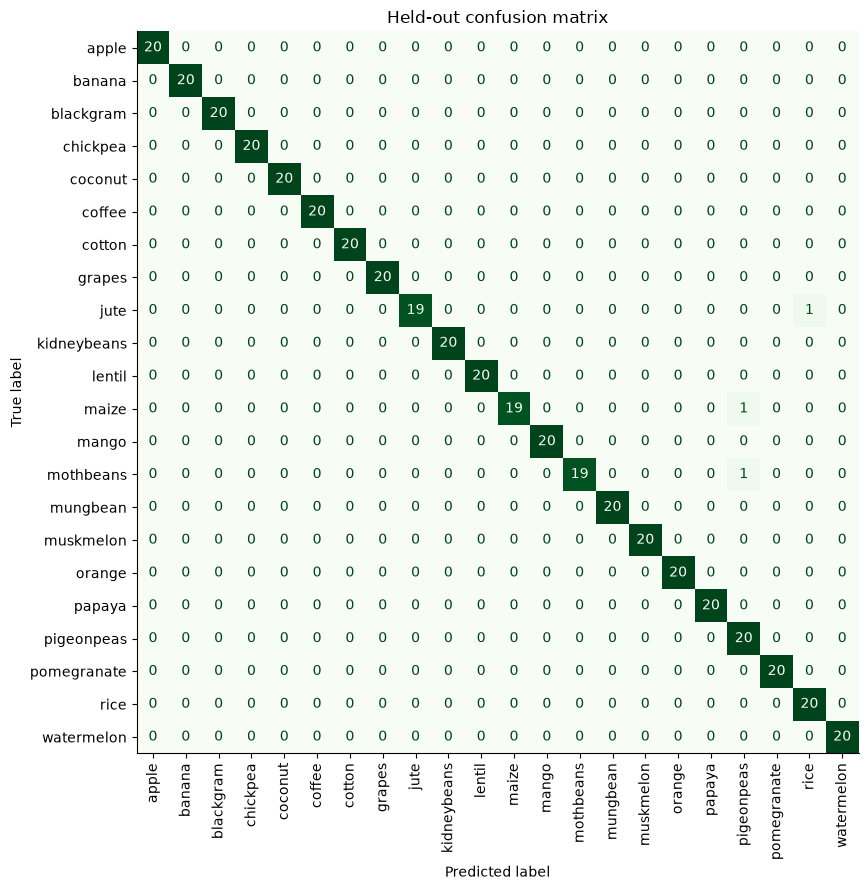

In [6]:
print(f"Test accuracy: {metrics['accuracy']:.2%}")
print(f"Macro F1: {metrics['macro_f1']:.4f}")
display(pd.DataFrame(metrics["classification_report"]).T.round(3))
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(
    np.array(metrics["confusion_matrix"]), display_labels=metrics["labels"]
).plot(ax=ax, cmap="Greens", xticks_rotation=90, colorbar=False)
ax.set_title("Held-out confusion matrix")
plt.tight_layout()
plt.show()

**Read the output:** Accuracy = correct predictions / all predictions. Precision = TP/(TP+FP), recall = TP/(TP+FN), and F1 is their harmonic mean. Macro F1 averages class F1 values equally; support is the number of test examples for each class. Strong diagonal counts mean more correct classifications. All scores describe this synthetic test set.

## Inspect model feature importance

**What we do:** Rank inputs by their contribution to tree impurity reduction.

**Why we do it:** This gives a starting point for discussing what the model uses. It is not a causal explanation and can be misleading for correlated or high-cardinality inputs.

,Feature,Importance
0,numeric__humidity,0.211165
1,numeric__rainfall,0.204394
2,numeric__K,0.169477
3,numeric__P,0.154126
4,numeric__N,0.126699
5,numeric__temperature,0.088145
6,numeric__ph,0.045995


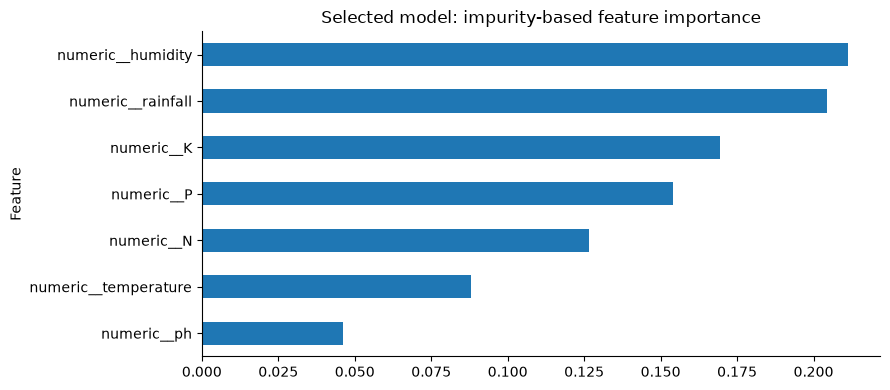

In [7]:
importance = feature_importance(bundle)
display(importance.head(12))
importance.head(12).sort_values("Importance").plot.barh(x="Feature", y="Importance", legend=False)
plt.title("Selected model: impurity-based feature importance")
plt.tight_layout()
plt.show()

**Read the output:** The prefix numeric__ identifies a numerical feature; category__ identifies an encoded category. Importance values are model-specific, not biological rules.

## Follow one prediction from inputs to output

**What we do:** Construct a named input dictionary, validate it and rank the model's class probabilities.

**Why we do it:** Named columns avoid accidentally swapping nitrogen with phosphorus or temperature with rainfall.

Top crop: rice
Range warnings: []


,Label,Model score (%)
0,rice,95.0
1,jute,5.0
2,blackgram,0.0


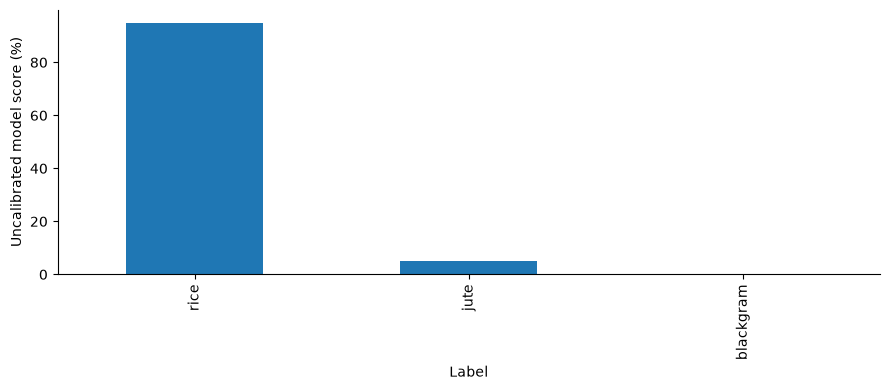

In [8]:
example = {"N": 85, "P": 45, "K": 40, "temperature": 25,
           "humidity": 82, "ph": 6.5, "rainfall": 220}
result = predict(KIND, example, bundle)
print("Top crop:", result["prediction"])
print("Range warnings:", result["warnings"])
display(result["ranking"].head(3).round(2))
result["ranking"].head(3).set_index("Label").plot.bar(legend=False)
plt.ylabel("Uncalibrated model score (%)")
plt.tight_layout()
plt.show()

**Read the output:** Scores come from predict_proba; they are not guaranteed suitability or field success. A model can be confident on unfamiliar inputs. Validation rejects impossible values and reports training-range warnings.

## Check invalid inputs and the saved model

**What we do:** Try an impossible humidity and compare the fresh model with the locally saved artifact.

**Why we do it:** The interface must reject invalid data, and reloading should preserve predictions.

In [9]:
from src.ml import load_model
try:
    predict(KIND, {**example, "humidity": 120}, bundle)
except ValueError as error:
    print("Expected validation error:", error)
saved = load_model(KIND)
print("Saved-model result:", predict(KIND, example, saved)["prediction"])
print("Same prediction:", predict(KIND, example, saved)["prediction"] == result["prediction"])

Expected validation error: humidity is outside its allowed range.
Saved-model result: rice


Same prediction: True


**Read the output:** The error is expected, and the two predictions should match. train_models.py writes locally trained joblib bundles; never load a model file from an untrusted source.

## Application connection
`app.py` collects these seven values in a form. `src/data.py` validates them; `src/ml.py` predicts.
The interface shows the top three scores and source crop notes. Only a compatible crop name can carry
forward to the other modules; numerical nutrient values are not copied across their different scales.

## Results, limitations and future work
Report the accuracy and macro F1 printed above, not a promised score. The current data has fixed profiles,
equal class counts and no regional/seasonal field variation. The rainfall period and N/P/K units need
documentation before meaningful real-world input mapping. Future work needs verified observations,
region-aware evaluation, probability calibration and expert review.

## Viva questions
**Why classification?** The output is one crop category.

**Why stratify?** It preserves the proportion of each crop in the training and test sets.

**Why not standardize the inputs?** Tree splits compare each input with thresholds; this pipeline does
not depend on distance between differently scaled features.

**Why compare a tree and forest?** A tree is a simple baseline; a forest can reduce variance by combining trees.

**Does 99% test accuracy mean 99% farm success?** No. It measures label agreement on this synthetic split.

**Exercise:** change rainfall while keeping other values fixed. Record rankings and warnings. Explain
why this is a model response rather than proof that changing rainfall would cause a particular outcome.